# Challenge 1: The banknote-authentication data set problem

We will perform a nearly realistic analysis of the data set bank note authentication that can be downloaded from this [link](https://archive.ics.uci.edu/dataset/267/banknote+authentication) or from the [github repo](https://github.com/LorenzoTonet/Intro_to_ML_26-27/blob/main/data/data_banknote_authentication.txt)

## Data set description

Data were extracted from images that were taken from genuine and forged banknote-like specimens. For digitization, an industrial camera usually used for print inspection was used. The final images have 400x 400 pixels. Due to the object lens and distance to the investigated object gray-scale pictures with a resolution of about 660 dpi were gained. Wavelet Transform tool were used to extract features from images.
These features are:
1. variance of Wavelet Transformed image (continuous) 
2. skewness of Wavelet Transformed image (continuous) 
3. curtosis of Wavelet Transformed image (continuous) 
4. entropy of image (continuous) 
5. class (integer)

## Task description
We have a binary classification problem. The assignment can be divided in several parts:
    
    1. Load the data and pretreatment.
    2. Data exploring by Unsupervised Learning techniques.
    3. Construction of several models of Supervised Learning.
    4. Assessment and evaluation

#### Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 1. Data pretreatment

Load the data and look at it: It is needed some kind of scaling? Why? Are the data points sorted in the original data set? Can it generate problems? How can this be solved?

</div>

#### 1.1 Loading and inspecting the data

In [2]:
# 1. I define the column names
columns = ["variance", "skewness", "curtosis", "entropy", "class"]

# 2. I load the dataset
df = pd.read_csv("data_banknote_authentication.txt", header=None, names=columns)

# 3. I check the dimensions and look at the first rows
print("Shape:", df.shape)
display(df.head())

# 4. I check for missing values
print("Missing values:\n", df.isna().sum())

# 5. I count the duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())

# 6. I look at how many banknotes there are per class
print("\nClass distribution:\n", df["class"].value_counts())

# 7. I remove the duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("\nShape after removal:", df.shape)

Shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Missing values:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicated rows: 24

Class distribution:
 class
0    762
1    610
Name: count, dtype: int64

Shape after removal: (1348, 5)


**Observations on the data**

The dataset has 1372 banknotes and no missing values. I removed 24 duplicated rows (all of class 0) to avoid having one copy in the training set and the other in the test set. 1348 rows remain: 738 of class 0 and 610 of class 1, so the classes are fairly balanced.

#### 1.2 Is scaling needed?

              mean       std      min      max
variance  0.445785  2.862906  -7.0421   6.8248
skewness  1.909039  5.868600 -13.7731  12.9516
curtosis  1.413578  4.328365  -5.2861  17.9274
entropy  -1.168712  2.085877  -8.5482   2.4495


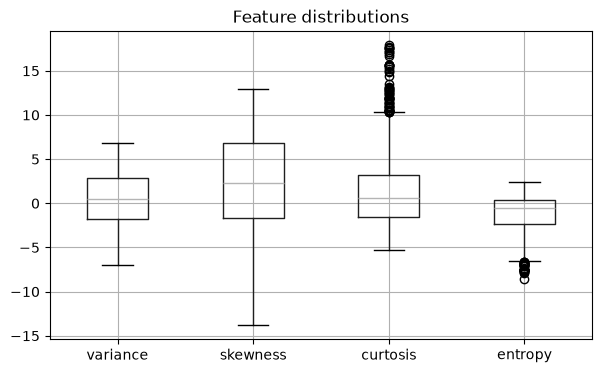

In [3]:
# 1. I separate the features from the class
X = df.drop(columns="class")
y = df["class"]

# 2. I compare mean, standard deviation and range of the features
print(X.describe().T[["mean", "std", "min", "max"]])

# 3. I visualize the distributions with a boxplot
X.boxplot(figsize=(7, 4))
plt.title("Feature distributions")
plt.show()

**Is some kind of scaling needed? Why?**

Yes. The features have different scales: the standard deviation of skewness (5.87) is almost three times that of entropy (2.09), and the ranges are also very different. From the boxplot I also notice some outliers, especially in curtosis and entropy.

Many of the methods I will use (PCA, k-means, DBSCAN, t-SNE, k-NN and regularized logistic regression) depend on distances or on variance: without scaling, the features with larger values would count more. For this reason I use a `StandardScaler`, which brings every feature to mean 0 and standard deviation 1. Naive Bayes and the decision tree, on the other hand, do not need it.

#### 1.3 Are the data sorted?

First row of class 1: 738


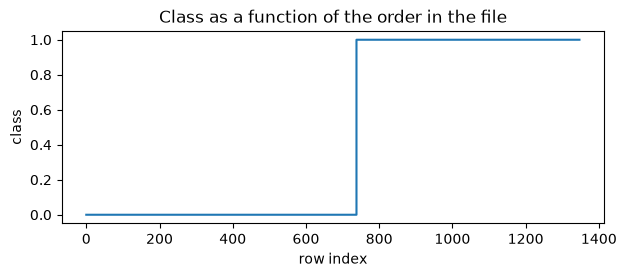

In [4]:
# 1. I check where class 1 starts
print("First row of class 1:", y.idxmax())

# 2. I plot the class as a function of the position in the file
plt.figure(figsize=(7, 2.5))
plt.plot(y.values, drawstyle="steps-post")
plt.xlabel("row index")
plt.ylabel("class")
plt.title("Class as a function of the order in the file")
plt.show()

**Are the data points sorted in the original dataset?**

Yes. From the plot I see that the class changes only once: the first 738 rows are of class 0 and the last 610 of class 1.

**Can it generate problems?**

Yes. If, for example, I took the last 372 rows as the test set, I would only have banknotes of class 1, and the results would be meaningless. The same would happen with cross-validation if the folds were taken in order.

**How can this be solved?**

I shuffle the rows randomly before splitting the data, fixing a seed to get reproducible results. In part 3 I also use a stratified split, so that every subset keeps the same proportion between the classes.

#### 1.4 Shuffling and standardizing

In [5]:
# 1. I shuffle the rows randomly
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
X = df_shuffled.drop(columns="class").values
y = df_shuffled["class"].values
print("First 20 classes after shuffling:", y[:20])

# 2. I standardize the features
X_scaled = StandardScaler().fit_transform(X)
print("Mean after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling:", X_scaled.std(axis=0).round(3))

First 20 classes after shuffling: [0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 0 0 0 0 1]
Mean after scaling: [0. 0. 0. 0.]
Std after scaling: [1. 1. 1. 1.]


**Result**

After shuffling, the classes are mixed, and after scaling all the features have mean 0 and standard deviation 1. Here I fit the scaler on the whole dataset because in part 2 I only explore the data; in part 3 I will fit it on the training set only, to avoid *data leakage*.

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 2. Unsupervised Learning

Use PCA and plot the two first components colouring according with the class. Are the classes linearly separable in this projection? What happens when I applied k-means with two classes in this space? And if I use all the coordinates? Try also t-SNE for projection and DBSCAN for the clustering and comment on the results.

</div>

#### 2.1 PCA on the first two components

Explained variance: [0.544 0.323 0.088 0.044]
Explained variance of the first two: 0.867


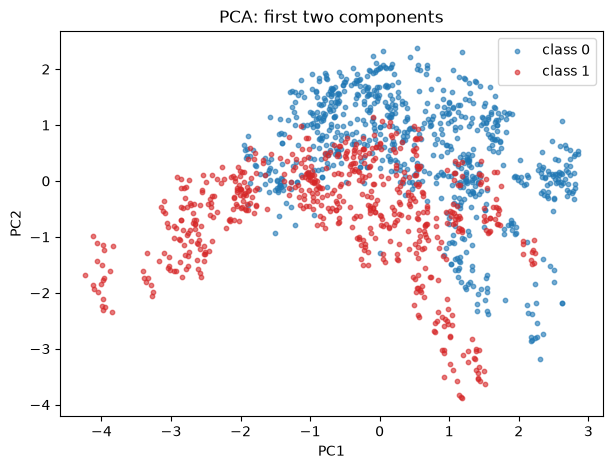

In [6]:
# 1. I apply PCA to the standardized data
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 2. I check how much variance each component explains
print("Explained variance:", pca.explained_variance_ratio_.round(3))
print("Explained variance of the first two:", pca.explained_variance_ratio_[:2].sum().round(3))

# 3. I plot the first two components, coloring by class
plt.figure(figsize=(7, 5))
for cls, color in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(X_pca[y == cls, 0], X_pca[y == cls, 1], s=10, alpha=0.6, c=color, label=f"class {cls}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: first two components")
plt.legend()
plt.show()

**Are the classes linearly separable in this projection?**

No. The first two components explain about 87% of the variance, and in the plot the classes tend to lie in different regions (class 1 in the bottom left, class 0 in the top right), but in the middle they overlap a lot: there is no line that separates them without misclassifying many points.

In my opinion the reason is that PCA does not use the labels: it looks for the directions of maximum variance, not the ones that best separate the classes.

#### 2.2 K-means on the first two components

,cluster 0,cluster 1
class 0,339,399
class 1,358,252


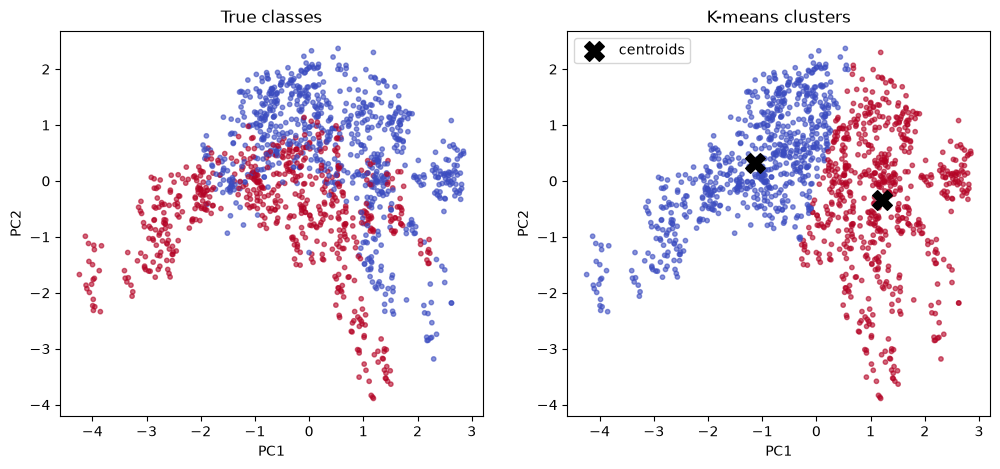

In [7]:
# 1. I apply k-means with 2 clusters on the first two components
kmeans_2d = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_2d = kmeans_2d.fit_predict(X_pca[:, :2])

# 2. I compare the clusters found with the true classes
table_2d = pd.crosstab(y, cluster_2d)
table_2d.index = ["class 0", "class 1"]
table_2d.columns = ["cluster 0", "cluster 1"]
display(table_2d)

# 3. I compare true classes and clusters graphically
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("True classes")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_2d, cmap="coolwarm", s=10, alpha=0.6)
ax[1].scatter(*kmeans_2d.cluster_centers_.T, c="black", marker="X", s=200, label="centroids")
ax[1].set_title("K-means clusters")
ax[1].legend()
for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()

**What happens when I apply k-means with two clusters in this space?**

The result is poor. K-means splits the points roughly with a vertical line around PC1 = 0, but this split does not correspond to the classes: from the table I see that both clusters contain many banknotes of both classes.

In my opinion the reason is that k-means looks for compact, spherical groups around a centroid, while here the classes have elongated shapes and overlap in the middle. So k-means simply cuts the cloud of points into two halves.

#### 2.3 K-means on all the coordinates

,cluster 0,cluster 1
class 0,402,336
class 1,254,356


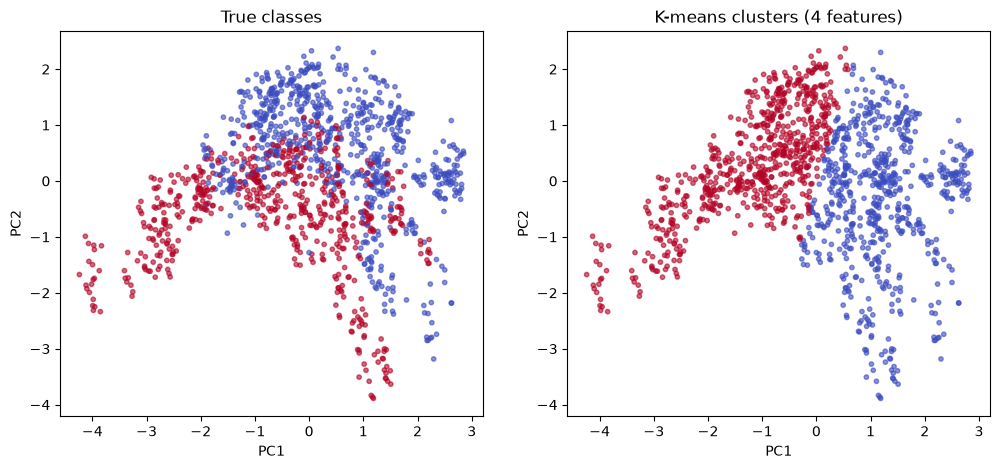

In [8]:
# 1. I apply k-means with 2 clusters on all 4 standardized features
kmeans_4d = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_4d = kmeans_4d.fit_predict(X_scaled)

# 2. I compare the clusters found with the true classes
table_4d = pd.crosstab(y, cluster_4d)
table_4d.index = ["class 0", "class 1"]
table_4d.columns = ["cluster 0", "cluster 1"]
display(table_4d)

# 3. I visualize the clusters on the plane of the first two components
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("True classes")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_4d, cmap="coolwarm", s=10, alpha=0.6)
ax[1].set_title("K-means clusters (4 features)")
for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()

**And if I use all the coordinates?**

Almost nothing changes: the table again shows clusters with many banknotes of both classes, and in the plot the split is almost identical to before, a cut around PC1 = 0. The colors are swapped, but only because k-means numbers the clusters arbitrarily.

In my opinion the result is similar because the first two components already explain 87% of the variance, so the distances used by k-means depend mostly on them. The problem stays the same: the classes do not form two compact groups.

#### 2.4 Projection with t-SNE

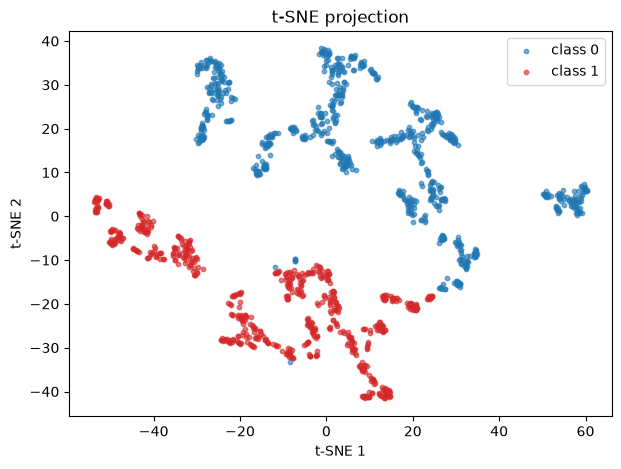

In [9]:
# 1. I project the standardized data into 2 dimensions with t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# 2. I plot the projection, coloring by class
plt.figure(figsize=(7, 5))
for cls, color in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(X_tsne[y == cls, 0], X_tsne[y == cls, 1], s=10, alpha=0.6, c=color, label=f"class {cls}")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE projection")
plt.legend()
plt.show()

**Comment on the t-SNE projection**

With t-SNE the two classes appear almost completely separated: class 0 is in the top right, class 1 in the bottom left, and each class is split into many small elongated groups.

t-SNE does not use the labels either, so this means that banknotes close to each other in the 4-dimensional space almost always belong to the same class. PCA could not show this because it is linear and only looks for the directions of maximum variance, while t-SNE preserves who is close to whom. This makes me think that k-NN will work well in part 3.

#### 2.5 Clustering with DBSCAN

Number of clusters: 13
Noise points: 42


,class 0,class 1
cluster,,
-1,28,14
0,5,486
1,0,36
2,658,0
3,24,0
4,11,0
5,0,9
6,0,10
7,0,10


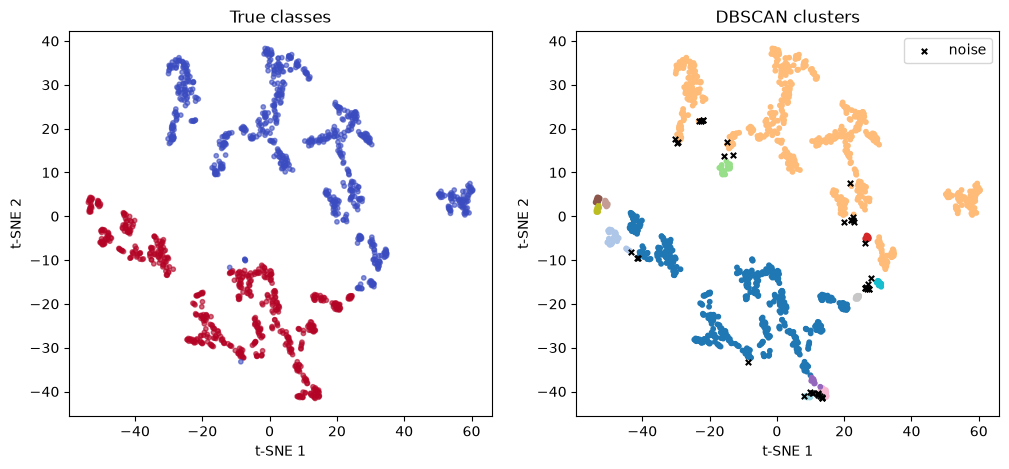

In [10]:
# 1. I apply DBSCAN to the standardized features
cluster_db = DBSCAN(eps=0.45, min_samples=8).fit_predict(X_scaled)
noise = cluster_db == -1
print("Number of clusters:", len(set(cluster_db[~noise])))
print("Noise points:", noise.sum())

# 2. I compare the clusters found with the true classes
table_db = pd.crosstab(cluster_db, y)
table_db.index.name = "cluster"
table_db.columns = ["class 0", "class 1"]
display(table_db)

# 3. I visualize the clusters on the t-SNE plane
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("True classes")
ax[1].scatter(X_tsne[~noise, 0], X_tsne[~noise, 1], c=cluster_db[~noise], cmap="tab20", s=10)
ax[1].scatter(X_tsne[noise, 0], X_tsne[noise, 1], c="black", marker="x", s=15, label="noise")
ax[1].set_title("DBSCAN clusters")
ax[1].legend()
for a in ax:
    a.set_xlabel("t-SNE 1")
    a.set_ylabel("t-SNE 2")
plt.show()

**Comment on the DBSCAN clustering**

I tried a few values of `eps` and chose 0.45: with smaller values DBSCAN finds a lot of small clusters and labels many points as noise, while with larger values the clusters of the two classes merge.

With `eps = 0.45` the result is much better than k-means. DBSCAN finds two large clusters that correspond almost exactly to the two classes (658 banknotes of class 0 and 486 of class 1, with only 5 errors), plus a few small groups, almost all of a single class, and 42 noise points.

In my opinion it works because DBSCAN does not look for spherical groups but follows the dense regions of the data, whatever their shape. However, the result depends a lot on `eps`.

Overall, from part 2 I understand that the classes are not separable in the PCA projection and do not form two compact groups, so k-means cannot find them; however, banknotes close to each other almost always belong to the same class, as t-SNE and DBSCAN show.

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 3. Supervised Learning

Generate a subset of the data of 372 elements that would be saved as test set. With the rest of the data generate the following models: Logistic Regression, Decision tree (use the ID3 algorithm), Naive Bayes and k-NN. 

Investigate the effect of regularization (when possible) and use cross validation for setting the hyper-parameters when needed. 

Compare the performances in terms of accuracy, precision, recall and F1-score on the test set. Comment these results at the light of those obtained from the Unsupervised Learning analysis. Could you propose a way to improve these results?

</div>

#### 3.1 Training and test split

In [11]:
# 1. I set aside 372 elements for the test set, keeping the class proportions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=372, stratify=y, random_state=42)

# 2. I check the dimensions and the class distribution
print("Training set:", X_train.shape, "| class 0:", (y_train == 0).sum(), "| class 1:", (y_train == 1).sum())
print("Test set:    ", X_test.shape, "| class 0:", (y_test == 0).sum(), "| class 1:", (y_test == 1).sum())

# 3. I fit the scaler on the training set only and apply it to both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: (976, 4) | class 0: 534 | class 1: 442
Test set:     (372, 4) | class 0: 204 | class 1: 168


**Result**

I split the data into 976 training and 372 test elements, using stratification: in both, class 1 is about 45%, as in the full dataset. The scaler is fitted on the training set only and then applied to the test set, so the test set stays completely "new" for the models.

#### 3.2 Logistic regression

Best C: 3.162
Mean CV accuracy: 0.9939


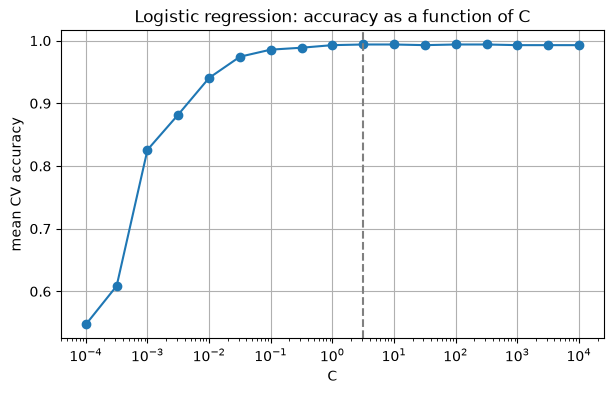

In [12]:
# 1. I define a stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. I try different values of C with cross-validation
C_values = np.logspace(-4, 4, 17)
grid_log = GridSearchCV(LogisticRegression(max_iter=1000), {"C": C_values}, cv=cv, scoring="accuracy")
grid_log.fit(X_train_scaled, y_train)
model_log = grid_log.best_estimator_
print("Best C:", round(grid_log.best_params_["C"], 3))
print("Mean CV accuracy:", round(grid_log.best_score_, 4))

# 3. I visualize the effect of regularization
plt.figure(figsize=(7, 4))
plt.semilogx(C_values, grid_log.cv_results_["mean_test_score"], marker="o")
plt.axvline(grid_log.best_params_["C"], color="gray", linestyle="--")
plt.xlabel("C")
plt.ylabel("mean CV accuracy")
plt.title("Logistic regression: accuracy as a function of C")
plt.grid(True)
plt.show()

**Effect of regularization**

In logistic regression the regularization is controlled by C: the smaller C, the stronger the regularization. With a very small C (0.0001) the coefficients are pushed almost to zero and the accuracy is about 55%, because the model always predicts the most frequent class. As C increases, the accuracy rises quickly and from C ≈ 1 onwards it stays stable around 99.3%. Cross-validation chooses C ≈ 3.16, with an accuracy of 99.4%.

It is interesting that a linear model works so well, given that in the PCA projection the classes were not linearly separable: the separation exists in the 4-dimensional space, but it is not visible in the first two components.

#### 3.3 Decision tree (ID3)

In [13]:
# I implement ID3 starting from the Lab-05 version, adapted to numpy arrays
class ID3:
    """ID3 tree for discrete features: one branch for each value of the feature."""

    def entropy(self, y):
        # 1. I compute the proportion of each class
        p = np.bincount(y) / len(y)
        p = p[p > 0]

        # 2. I sum -p * log2(p) over all the classes
        return -np.sum(p * np.log2(p))

    def information_gain(self, X, y, j):
        # 1. I compute the weighted mean entropy of the subsets created by feature j
        weighted_entropy = 0
        for value in np.unique(X[:, j]):
            mask = X[:, j] == value
            weighted_entropy += mask.mean() * self.entropy(y[mask])

        # 2. The gain is how much the entropy decreases
        return self.entropy(y) - weighted_entropy

    def build(self, X, y, available_features):
        most_frequent = np.bincount(y).argmax()

        # 1. I stop if the node is pure or if there are no features left: I create a leaf
        if len(np.unique(y)) == 1 or len(available_features) == 0:
            return most_frequent

        # 2. I choose the feature with the maximum information gain
        j = max(available_features, key=lambda f: self.information_gain(X, y, f))

        # 3. I create one branch for each value of the feature and build the subtrees
        branches = {}
        for value in np.unique(X[:, j]):
            mask = X[:, j] == value
            branches[value] = self.build(X[mask], y[mask], [f for f in available_features if f != j])
        return {"feature": j, "branches": branches, "default": most_frequent}

    def fit(self, X, y):
        self.tree = self.build(X, y, list(range(X.shape[1])))
        return self

    def predict_one(self, x, node):
        # 1. I go down the tree until I reach a leaf
        while isinstance(node, dict):
            # 2. If the value was never seen, I use the most frequent class of the node
            node = node["branches"].get(x[node["feature"]], node["default"])
        return node

    def predict(self, X):
        return np.array([self.predict_one(x, self.tree) for x in X])

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

Best number of bins: 8
Mean CV accuracy: 0.9836


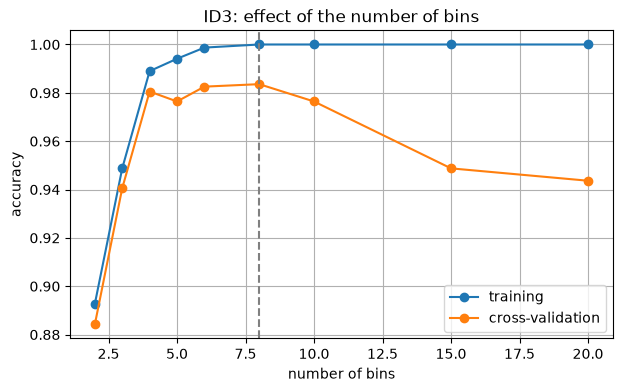

In [14]:
# 1. I define a function that splits each feature into n_bins intervals
def discretize(X_fit, X_apply, n_bins):
    X_fit_d = np.zeros_like(X_fit, dtype=int)
    X_apply_d = np.zeros_like(X_apply, dtype=int)
    for j in range(X_fit.shape[1]):
        # I compute the bin edges with quantiles, on the fit data only
        edges = np.quantile(X_fit[:, j], np.linspace(0, 1, n_bins + 1))[1:-1]
        # I assign to each value the index of its bin
        X_fit_d[:, j] = np.digitize(X_fit[:, j], edges)
        X_apply_d[:, j] = np.digitize(X_apply[:, j], edges)
    return X_fit_d, X_apply_d

# 2. I try different numbers of bins with cross-validation
bin_values = [2, 3, 4, 5, 6, 8, 10, 15, 20]
acc_train, acc_cv = [], []
for n_bins in bin_values:
    acc_train_fold, acc_cv_fold = [], []
    for idx_train, idx_val in cv.split(X_train, y_train):
        X_tr_d, X_val_d = discretize(X_train[idx_train], X_train[idx_val], n_bins)
        tree = ID3().fit(X_tr_d, y_train[idx_train])
        acc_train_fold.append(tree.score(X_tr_d, y_train[idx_train]))
        acc_cv_fold.append(tree.score(X_val_d, y_train[idx_val]))
    acc_train.append(np.mean(acc_train_fold))
    acc_cv.append(np.mean(acc_cv_fold))

best_bins = bin_values[np.argmax(acc_cv)]
print("Best number of bins:", best_bins)
print("Mean CV accuracy:", round(max(acc_cv), 4))

# 3. I visualize the effect of the number of bins
plt.figure(figsize=(7, 4))
plt.plot(bin_values, acc_train, marker="o", label="training")
plt.plot(bin_values, acc_cv, marker="o", label="cross-validation")
plt.axvline(best_bins, color="gray", linestyle="--")
plt.xlabel("number of bins")
plt.ylabel("accuracy")
plt.title("ID3: effect of the number of bins")
plt.legend()
plt.grid(True)
plt.show()

# 4. I train the final model on the whole training set with the best number of bins
X_train_d, X_test_d = discretize(X_train, X_test, best_bins)
model_id3 = ID3().fit(X_train_d, y_train)

**Effect of regularization**

I used my own implementation of ID3, based on the one from Lab-05. Since ID3 creates one branch for each value of a feature, it only works with discrete features: for this reason I first split each feature into intervals (bins), computing the edges on the training set only.

The number of bins acts as regularization. With few bins the tree is too simple and the accuracy is low both on the training set and in CV; with too many bins the training accuracy reaches 1.0 but the CV accuracy drops (94% with 20 bins), because the tree memorizes the training set (overfitting). Cross-validation chooses 8 bins, with an accuracy of 98.4%.

#### 3.4 Naive Bayes

In [15]:
# 1. I try different values of var_smoothing with cross-validation
smoothing_values = np.logspace(-9, 0, 10)
grid_nb = GridSearchCV(GaussianNB(), {"var_smoothing": smoothing_values}, cv=cv, scoring="accuracy")
grid_nb.fit(X_train, y_train)
model_nb = grid_nb.best_estimator_
print("Best var_smoothing:", grid_nb.best_params_["var_smoothing"])
print("Mean CV accuracy:", round(grid_nb.best_score_, 4))

# 2. I look at how the accuracy changes with var_smoothing
display(pd.DataFrame({"var_smoothing": smoothing_values,
                      "CV accuracy": grid_nb.cv_results_["mean_test_score"].round(4)}))

# 3. I check the correlation between the features
display(pd.DataFrame(X_train, columns=columns[:4]).corr().round(2))

Best var_smoothing: 0.01
Mean CV accuracy: 0.8452


,var_smoothing,CV accuracy
0,1.000000e-09,0.8422
1,1.000000e-08,0.8422
2,1.000000e-07,0.8422
3,1.000000e-06,0.8422
4,1.000000e-05,0.8422
5,1.000000e-04,0.8422
6,1.000000e-03,0.8422
7,1.000000e-02,0.8452
8,1.000000e-01,0.8391
9,1.000000e+00,0.7091


,variance,skewness,curtosis,entropy
variance,1.00,0.27,-0.38,0.27
skewness,0.27,1.00,-0.78,-0.53
curtosis,-0.38,-0.78,1.00,0.31
entropy,0.27,-0.53,0.31,1.00


**Effect of regularization**

Naive Bayes has no real regularization, but the `var_smoothing` parameter adds a small amount to the variances to make them more stable. From the table I see that it changes very little: the accuracy stays around 84% for small values, CV chooses 0.01 (84.5%), and only with large values (1.0) does it drop to 71%.

The result is much lower than the other models, in my opinion for two reasons. Naive Bayes assumes that the features are independent, but skewness and curtosis have a correlation of −0.78. Moreover, it describes each feature, within each class, with a single Gaussian, while from the t-SNE plot I saw that each class is made of many separate small groups.

#### 3.5 k-NN

Best k: 3
Mean CV accuracy: 0.9959


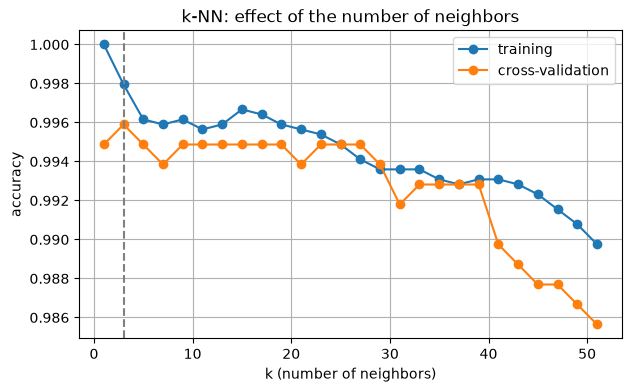

In [16]:
# 1. I try different values of k with cross-validation
k_values = range(1, 52, 2)
grid_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": k_values}, cv=cv,
                        scoring="accuracy", return_train_score=True)
grid_knn.fit(X_train_scaled, y_train)
model_knn = grid_knn.best_estimator_
print("Best k:", grid_knn.best_params_["n_neighbors"])
print("Mean CV accuracy:", round(grid_knn.best_score_, 4))

# 2. I compare training and cross-validation accuracy as k changes
plt.figure(figsize=(7, 4))
plt.plot(k_values, grid_knn.cv_results_["mean_train_score"], marker="o", label="training")
plt.plot(k_values, grid_knn.cv_results_["mean_test_score"], marker="o", label="cross-validation")
plt.axvline(grid_knn.best_params_["n_neighbors"], color="gray", linestyle="--")
plt.xlabel("k (number of neighbors)")
plt.ylabel("accuracy")
plt.title("k-NN: effect of the number of neighbors")
plt.legend()
plt.grid(True)
plt.show()

**Effect of regularization**

For k-NN the regularization is the number of neighbors k. With k = 1 the training accuracy is 1.0, because each point is its own nearest neighbor; as k increases, the model averages over more neighbors and the boundary between the classes becomes smoother. Cross-validation chooses k = 3, with an accuracy of 99.6%, the highest among all the models. For large k the accuracy decreases slowly (98.6% with k = 51), because the model starts to consider points that are far away as well.

However, the curves are almost flat: the accuracy stays above 98.5% for every k. This confirms what I had seen with t-SNE and DBSCAN: banknotes close to each other almost always belong to the same class.

#### 3.6 Comparison of the models on the test set

,accuracy,precision,recall,F1-score
Logistic regression,0.989,0.982,0.994,0.988
ID3,0.995,0.988,1.000,0.994
Naive Bayes,0.871,0.895,0.810,0.850
k-NN,1.000,1.000,1.000,1.000


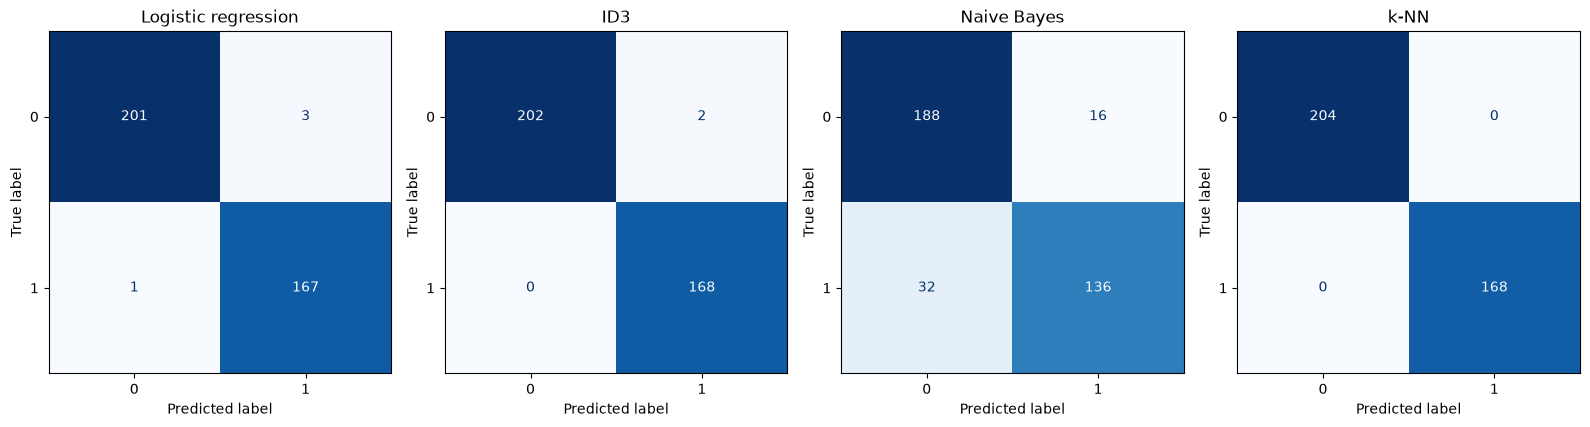

In [17]:
# 1. I compute the predictions of each model on the test set
predictions = {
    "Logistic regression": model_log.predict(X_test_scaled),
    "ID3": model_id3.predict(X_test_d),
    "Naive Bayes": model_nb.predict(X_test),
    "k-NN": model_knn.predict(X_test_scaled),
}

# 2. I compute the metrics for each model
metrics = pd.DataFrame({name: {"accuracy": accuracy_score(y_test, y_pred),
                               "precision": precision_score(y_test, y_pred),
                               "recall": recall_score(y_test, y_pred),
                               "F1-score": f1_score(y_test, y_pred)}
                        for name, y_pred in predictions.items()}).T
display(metrics.round(3))

# 3. I show the confusion matrix of each model
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (name, y_pred) in zip(ax, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout()
plt.show()

**Comparison of the models on the test set**

k-NN correctly classifies all 372 banknotes of the test set. ID3 misclassifies 2 and logistic regression 4, so they also work very well. Naive Bayes, instead, misclassifies 48 (accuracy 87.1%) and above all misses 32 of class 1, so its recall drops to 81%.

The results are consistent with those of cross-validation, so the models did not overfit. However, the test set is small: between k-NN, ID3 and logistic regression the difference is 2–4 banknotes, so I cannot say for sure which one is really the best.

**Comment in light of the unsupervised analysis**

- **k-NN** is the best, as I expected from t-SNE and DBSCAN: banknotes that are close to each other almost always belong to the same class, which is exactly the assumption k-NN is based on.
- **Logistic regression** works well even though the classes were not linearly separable in the PCA projection: the linear separation exists in 4 dimensions, but it is not visible in the first two components.
- **Naive Bayes** performs poorly because its assumptions are not met: the features are correlated and each class is made of many small groups, not a single Gaussian.
- **K-means** could not find the classes because they do not form two compact groups, but the local structure of the data distinguishes them well, and the supervised methods exploit it.

**Could you propose a way to improve these results?**

- **Naive Bayes**: decorrelate the features first, for example with PCA, or estimate the distributions without assuming they are Gaussian.
- **Logistic regression**: add polynomial features, so that the boundary between the classes can be curved.
- **ID3**: choose the bin thresholds based on information gain instead of quantiles, or combine many trees (random forest).
- **Evaluation**: since the test set is small, repeat the training/test split with different seeds and average the results.